In [1]:

import pandas as pd
import matplotlib.pyplot as plt

print("Pandas version:", pd.__version__)
print("Python environment is ready!")


Pandas version: 2.2.3
Python environment is ready!


In [2]:
# Download gene-expression data from NCBI GEO

url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE32nnn/GSE32571/matrix/GSE32571_series_matrix.txt.gz"

expression = pd.read_csv(
    url,
    sep="\t",
    compression="gzip",
    comment="!",
    index_col=0
)

# Check the size of our dataset
print("Dataset dimensions:", expression.shape)

# Display the first 5 rows and 5 columns
display(expression.iloc[:5, :5])

Dataset dimensions: (48652, 98)


,GSM807224,GSM807225,GSM807226,GSM807227,GSM807228
ID_REF,,,,,
ILMN_1343291,14.842827,14.595900,14.765234,15.051098,14.947501
ILMN_1343295,10.609650,11.293558,10.823892,11.034346,10.832781
ILMN_1651199,5.935210,5.933879,5.951948,5.903561,6.136344
ILMN_1651209,6.237834,6.220986,6.286124,6.025119,6.343364
ILMN_1651210,5.997515,5.905731,5.923981,6.089467,6.094237


In [3]:
import gzip
import csv
from urllib.request import urlopen

# Read sample descriptions from the GEO file
with urlopen(url) as response:
    with gzip.open(response, "rt") as file:
        for line in file:
            if line.startswith("!Sample_title\t"):
                titles = next(csv.reader([line], delimiter="\t"))[1:]
                break

# Create a table describing our samples
samples = pd.DataFrame({
    "Sample_ID": expression.columns,
    "Sample_title": titles
})

# Display the first 10 samples
display(samples.head(10))

,Sample_ID,Sample_title
0,GSM807224,Human_Prostate_Tissue_Benign_IMGUS_DKFZ_01
1,GSM807225,Human_Prostate_Tissue_Tumor_IMGUS_DKFZ_02
2,GSM807226,Human_Prostate_Tissue_Tumor_IMGUS_DKFZ_03
3,GSM807227,Human_Prostate_Tissue_Benign_IMGUS_DKFZ_04
4,GSM807228,Human_Prostate_Tissue_Tumor_IMGUS_DKFZ_05
5,GSM807229,Human_Prostate_Tissue_Benign_IMGUS_DKFZ_06
6,GSM807230,Human_Prostate_Tissue_Benign_IMGUS_DKFZ_07
7,GSM807231,Human_Prostate_Tissue_Benign_IMGUS_DKFZ_08
8,GSM807232,Human_Prostate_Tissue_Benign_IMGUS_DKFZ_09
9,GSM807233,Human_Prostate_Tissue_Tumor_IMGUS_DKFZ_10


Number of samples in each group:
Group
Tumor     59
Benign    39
Name: count, dtype: int64


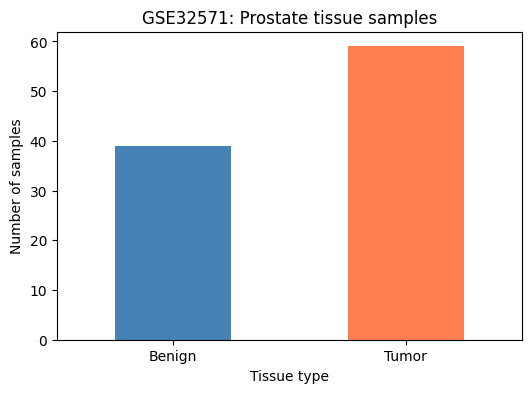

In [4]:
# Identify tissue type from sample titles
samples["Group"] = samples["Sample_title"].str.extract(
    r"_(Benign|Tumor)_"
)

# Count samples in each group
counts = samples["Group"].value_counts()

print("Number of samples in each group:")
print(counts)

# Create a bar chart
plt.figure(figsize=(6, 4))

counts.reindex(["Benign", "Tumor"]).plot(
    kind="bar",
    color=["steelblue", "coral"]
)

plt.title("GSE32571: Prostate tissue samples")
plt.xlabel("Tissue type")
plt.ylabel("Number of samples")
plt.xticks(rotation=0)
plt.show()

In [5]:
import io

# Download the Illumina probe annotation
gpl_url = "https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPL6nnn/GPL6947/soft/GPL6947_family.soft.gz"

table_lines = []
in_table = False

with urlopen(gpl_url) as response:
    with gzip.open(response, "rt", errors="replace") as file:
        for line in file:
            if line.startswith("!platform_table_begin"):
                in_table = True
                continue
            if line.startswith("!platform_table_end"):
                break
            if in_table:
                table_lines.append(line)

# Convert the annotation into a pandas DataFrame
annotation = pd.read_csv(
    io.StringIO("".join(table_lines)),
    sep="\t",
    usecols=["ID", "Symbol"],
    dtype=str
)

print("Annotation dimensions:", annotation.shape)
display(annotation.head())

Annotation dimensions: (49576, 2)


,ID,Symbol
0,ILMN_1725881,LOC23117
1,ILMN_1910180,NaN
2,ILMN_1804174,FCGR2B
3,ILMN_1796063,TRIM44
4,ILMN_1811966,LOC653895


In [6]:
# Our genes of interest
upr_genes = [
    "ERN1",      # IRE1alpha
    "EIF2AK3",   # PERK
    "ATF6",
    "HSPA5",     # BiP
    "ATF4",
    "DDIT3"      # CHOP
]

# Find probes associated with these genes
# Keep only probes present in our expression dataset
upr_probes = annotation[
    annotation["Symbol"].isin(upr_genes)
    & annotation["ID"].isin(expression.index)
].copy()

# Sort and display the results
upr_probes = upr_probes.sort_values("Symbol")

print("Probes found for our UPR genes:")
display(upr_probes)

print("\nNumber of probes per gene:")
print(
    upr_probes.groupby("Symbol")
    .size()
    .reindex(upr_genes, fill_value=0)
)

Probes found for our UPR genes:


,ID,Symbol
10545,ILMN_1783394,ATF4
29050,ILMN_1672128,ATF4
39966,ILMN_2358457,ATF4
16757,ILMN_1703471,ATF6
11028,ILMN_1676984,DDIT3
9427,ILMN_1724984,EIF2AK3
15227,ILMN_1698404,ERN1
36520,ILMN_1731231,ERN1
14175,ILMN_1773865,HSPA5



Number of probes per gene:
Symbol
ERN1       2
EIF2AK3    1
ATF6       1
HSPA5      1
ATF4       3
DDIT3      1
dtype: int64


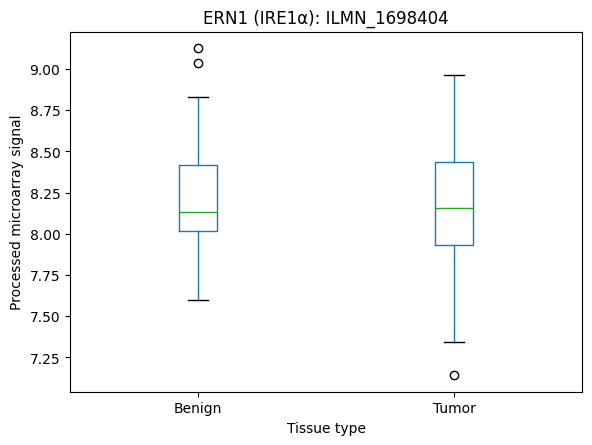

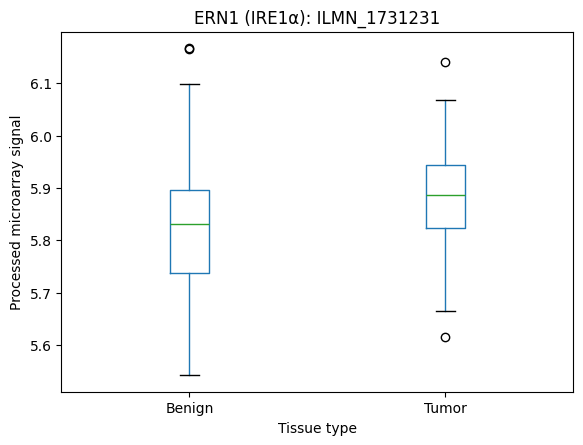

In [7]:
# Find the two ERN1 probes
ern1_ids = upr_probes.loc[
    upr_probes["Symbol"] == "ERN1", "ID"
].tolist()

# Get ERN1 expression across all samples
ern1_values = expression.loc[ern1_ids].T

# Add tissue type information
ern1_values["Group"] = samples.set_index("Sample_ID").loc[
    ern1_values.index, "Group"
].values

# Plot each ERN1 probe separately
for probe in ern1_ids:

    ern1_values.boxplot(
        column=probe,
        by="Group",
        grid=False
    )

    plt.title(f"ERN1 (IRE1α): {probe}")
    plt.suptitle("")
    plt.xlabel("Tissue type")
    plt.ylabel("Processed microarray signal")
    plt.show()

In [8]:
# Calculate median ERN1 expression in each group
summary = ern1_values.groupby("Group")[ern1_ids].median().T

# Calculate the difference between tumor and benign
summary["Tumor_minus_Benign"] = (
    summary["Tumor"] - summary["Benign"]
)

print("ERN1 expression summary:")
display(summary.round(3))

# Check whether the two ERN1 probes agree
print("Correlation between ERN1 probes:")
display(ern1_values[ern1_ids].corr().round(3))

ERN1 expression summary:


Group,Benign,Tumor,Tumor_minus_Benign
ID_REF,,,
ILMN_1698404,8.132,8.156,0.024
ILMN_1731231,5.831,5.887,0.055


Correlation between ERN1 probes:


ID_REF,ILMN_1698404,ILMN_1731231
ID_REF,,
ILMN_1698404,1.000,-0.215
ILMN_1731231,-0.215,1.000


In [9]:
# Extract expression values for all UPR probes
upr_values = expression.loc[upr_probes["ID"]].T

# Add sample group information
upr_values["Group"] = samples.set_index("Sample_ID").loc[
    upr_values.index, "Group"
].values

# Calculate median expression for each probe
median_table = upr_values.groupby("Group")[
    upr_probes["ID"].tolist()
].median().T

# Add gene names
median_table["Gene"] = median_table.index.map(
    upr_probes.set_index("ID")["Symbol"]
)

# Calculate tumor vs benign differences
median_table["Tumor_minus_Benign"] = (
    median_table["Tumor"] - median_table["Benign"]
)

# Display results
display(
    median_table[
        ["Gene", "Benign", "Tumor", "Tumor_minus_Benign"]
    ].sort_values("Gene").round(3)
)

Group,Gene,Benign,Tumor,Tumor_minus_Benign
ID_REF,,,,
ILMN_1783394,ATF4,6.580,6.855,0.275
ILMN_1672128,ATF4,10.912,11.067,0.154
ILMN_2358457,ATF4,6.850,7.007,0.157
ILMN_1703471,ATF6,8.249,8.140,-0.109
ILMN_1676984,DDIT3,8.100,8.017,-0.083
ILMN_1724984,EIF2AK3,6.391,6.393,0.001
ILMN_1698404,ERN1,8.132,8.156,0.024
ILMN_1731231,ERN1,5.831,5.887,0.055
ILMN_1773865,HSPA5,9.830,9.768,-0.062


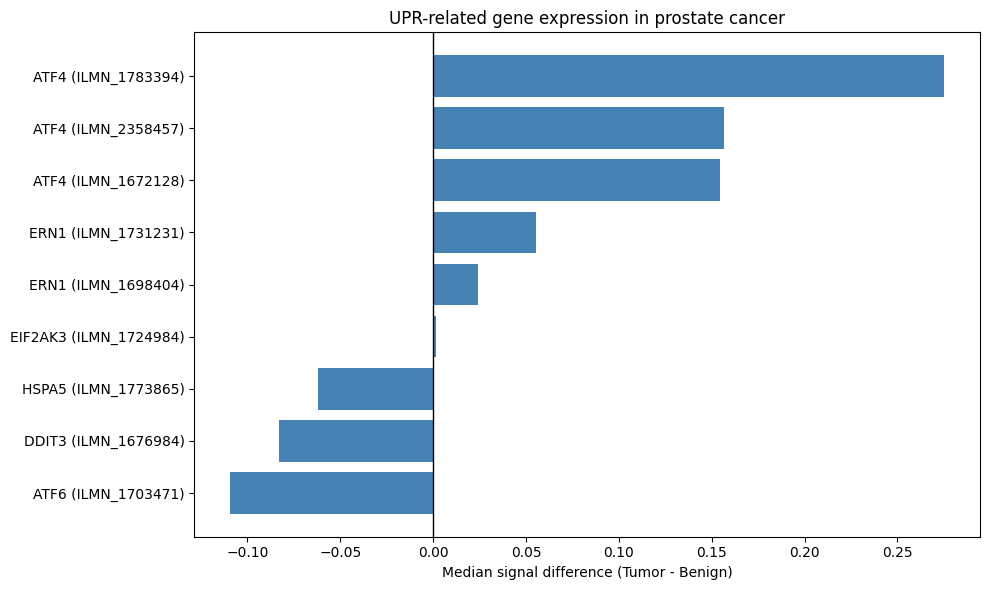

In [10]:
# Prepare data for visualization
plot_data = median_table[
    ["Gene", "Tumor_minus_Benign"]
].copy()

# Create a label for each probe
plot_data["Label"] = (
    plot_data["Gene"] + " (" + plot_data.index + ")"
)

# Sort by difference
plot_data = plot_data.sort_values("Tumor_minus_Benign")

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Label"],
    plot_data["Tumor_minus_Benign"],
    color="steelblue"
)

# Add reference line at zero
plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Median signal difference (Tumor - Benign)")
plt.title("UPR-related gene expression in prostate cancer")

plt.tight_layout()
plt.show()

In [11]:
# Find the three ATF4 probes
atf4_ids = upr_probes.loc[
    upr_probes["Symbol"] == "ATF4", "ID"
].tolist()

# Extract ATF4 expression values
atf4_values = expression.loc[atf4_ids].T

# Calculate correlation between probes
print("Correlation between ATF4 probes:")
display(atf4_values.corr().round(3))

Correlation between ATF4 probes:


ID_REF,ILMN_1783394,ILMN_1672128,ILMN_2358457
ID_REF,,,
ILMN_1783394,1.000,0.037,0.133
ILMN_1672128,0.037,1.000,0.736
ILMN_2358457,0.133,0.736,1.000


In [12]:
# Read additional information about the microarray probes
probe_details = pd.read_csv(
    io.StringIO("".join(table_lines)),
    sep="\t",
    usecols=[
        "ID",
        "Symbol",
        "RefSeq_ID",
        "Entrez_Gene_ID",
        "Probe_Type",
        "Probe_Start"
    ],
    dtype=str
)

# Show annotation details for our ATF4 probes
atf4_details = probe_details[
    probe_details["ID"].isin(atf4_ids)
]

display(atf4_details)

,ID,RefSeq_ID,Entrez_Gene_ID,Symbol,Probe_Type,Probe_Start
10545,ILMN_1783394,NM_001675.2,468,ATF4,I,593
29050,ILMN_1672128,NM_001675.2,468,ATF4,A,1934
39966,ILMN_2358457,NM_182810.1,468,ATF4,A,824


### ATF4 probe-level quality assessment

Three probes annotated to ATF4 were identified in GSE32571.

Two A-type probes (ILMN_1672128 and ILMN_2358457)
showed relatively strong positive correlation (r = 0.736).

An I-type, isoform-specific probe (ILMN_1783394)
showed weak correlations with both A-type probes
(r = 0.037 and r = 0.133).

According to Illumina documentation, A-type probes
are designed to detect all known transcript isoforms,
whereas I-type probes are designed for isoform-specific
detection.

The differences may reflect transcript-specific
measurements or technical factors.

All three probes are retained for further evaluation.
Detection quality and probe specificity require
additional investigation before drawing conclusions
about ATF4 expression in prostate cancer.

In [13]:
# Download the original GEO sample tables
soft_url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE32nnn/GSE32571/soft/GSE32571_family.soft.gz"

wanted_probes = set(upr_probes["ID"])

records = []
sample_id = None
inside_table = False

print("Reading GEO detection data. Please wait...")

with urlopen(soft_url) as response:
    with gzip.open(response, "rt", errors="replace") as file:

        for line in file:
            line = line.rstrip("\r\n")

            # Identify the current sample
            if line.startswith("^SAMPLE = "):
                sample_id = line.split(" = ", 1)[1]
                inside_table = False

            # Find the beginning of its measurement table
            elif line.lower().startswith("!sample_table_begin"):
                inside_table = True
                headers = next(file).rstrip("\r\n").split("\t")
                probe_col = headers.index("ID_REF")
                pval_col = headers.index("Detection.Pval")

            # Find the end of the measurement table
            elif line.lower().startswith("!sample_table_end"):
                inside_table = False

            # Extract only our UPR probes
            elif inside_table and sample_id:
                values = line.split("\t")

                if values[probe_col] in wanted_probes:
                    records.append((
                        sample_id,
                        values[probe_col],
                        values[pval_col]
                    ))

# Convert results into a pandas DataFrame
detection = pd.DataFrame(
    records,
    columns=["Sample_ID", "Probe_ID", "Detection_Pval"]
)

detection["Detection_Pval"] = pd.to_numeric(
    detection["Detection_Pval"],
    errors="coerce"
)

print("Detection records extracted:", len(detection))
display(detection.head(10))

Reading GEO detection data. Please wait...
Detection records extracted: 882


,Sample_ID,Probe_ID,Detection_Pval
0,GSM807224,ILMN_1676984,5.980000e-25
1,GSM807224,ILMN_1724984,5.030000e-06
2,GSM807224,ILMN_1773865,6.890000e-14
3,GSM807224,ILMN_1698404,5.050000e-10
4,GSM807224,ILMN_1672128,1.450000e-33
5,GSM807224,ILMN_1731231,5.652059e-02
6,GSM807224,ILMN_1703471,4.900000e-25
7,GSM807224,ILMN_1783394,1.090000e-07
8,GSM807224,ILMN_2358457,5.320000e-10
9,GSM807225,ILMN_1676984,8.900000e-29


In [14]:
# Add gene names and sample groups
detection["Gene"] = detection["Probe_ID"].map(
    upr_probes.set_index("ID")["Symbol"]
)

detection["Group"] = detection["Sample_ID"].map(
    samples.set_index("Sample_ID")["Group"]
)

# Check for missing detection values
print(
    "Missing detection p-values:",
    detection["Detection_Pval"].isna().sum()
)

# A probe is considered detected when p < 0.05
detection["Detected"] = detection["Detection_Pval"].lt(0.05)

# Keep missing p-values separate from non-detections
detection["Detected"] = detection["Detected"].where(
    detection["Detection_Pval"].notna()
)

# Calculate the detection percentage for each group
detection_rates = (
    detection.groupby(["Gene", "Probe_ID", "Group"])["Detected"]
    .mean()
    .mul(100)
    .unstack("Group")
    .round(1)
)

print("Percentage of samples with detected expression:")
display(detection_rates)

Missing detection p-values: 0
Percentage of samples with detected expression:


Group                 Benign  Tumor
Gene    Probe_ID                   
ATF4    ILMN_1672128   100.0  100.0
        ILMN_1783394    69.2   81.4
        ILMN_2358457    94.9   91.5
ATF6    ILMN_1703471   100.0  100.0
DDIT3   ILMN_1676984   100.0  100.0
EIF2AK3 ILMN_1724984    79.5   79.7
ERN1    ILMN_1698404   100.0  100.0
        ILMN_1731231    33.3   27.1
HSPA5   ILMN_1773865   100.0  100.0

In [15]:
# Prepare detection-rate information
qc_rates = detection_rates.reset_index().set_index("Probe_ID")

qc_rates = qc_rates.rename(columns={
    "Benign": "Detected_benign_pct",
    "Tumor": "Detected_tumor_pct"
})

# Combine expression differences with detection rates
qc_summary = median_table.join(
    qc_rates[
        ["Detected_benign_pct", "Detected_tumor_pct"]
    ]
)

qc_summary.index.name = "Probe_ID"

# Display the complete summary
display(
    qc_summary[
        [
            "Gene",
            "Benign",
            "Tumor",
            "Tumor_minus_Benign",
            "Detected_benign_pct",
            "Detected_tumor_pct"
        ]
    ].sort_values("Gene").round(2)
)

Group,Gene,Benign,Tumor,Tumor_minus_Benign,Detected_benign_pct,Detected_tumor_pct
Probe_ID,,,,,,
ILMN_1783394,ATF4,6.58,6.85,0.28,69.2,81.4
ILMN_1672128,ATF4,10.91,11.07,0.15,100.0,100.0
ILMN_2358457,ATF4,6.85,7.01,0.16,94.9,91.5
ILMN_1703471,ATF6,8.25,8.14,-0.11,100.0,100.0
ILMN_1676984,DDIT3,8.10,8.02,-0.08,100.0,100.0
ILMN_1724984,EIF2AK3,6.39,6.39,0.00,79.5,79.7
ILMN_1698404,ERN1,8.13,8.16,0.02,100.0,100.0
ILMN_1731231,ERN1,5.83,5.89,0.06,33.3,27.1
ILMN_1773865,HSPA5,9.83,9.77,-0.06,100.0,100.0


In [16]:
# Examine sample metadata fields
metadata_preview = []

with urlopen(url) as response:
    with gzip.open(response, "rt") as file:

        for line in file:

            if line.startswith("!series_matrix_table_begin"):
                break

            if line.startswith("!Sample_"):

                values = next(
                    csv.reader([line], delimiter="\t")
                )

                field = values[0]

                # Focus on biologically relevant metadata
                if any(word in field.lower() for word in [
                    "title",
                    "characteristics",
                    "description",
                    "relation",
                    "source_name"
                ]):

                    metadata_preview.append({
                        "Field": field,
                        "Sample_1": values[1][:120],
                        "Sample_2": values[2][:120]
                    })

# Display available metadata
metadata_table = pd.DataFrame(metadata_preview)

display(metadata_table)

,Field,Sample_1,Sample_2
0,!Sample_title,Human_Prostate_Tissue_Benign_IMGUS_DKFZ_01,Human_Prostate_Tissue_Tumor_IMGUS_DKFZ_02
1,!Sample_source_name_ch1,Human_Prostate_Tissue_Benign,Human_Prostate_Tissue_Tumor
2,!Sample_characteristics_ch1,tissue: prostate,tissue: prostate
3,!Sample_characteristics_ch1,disease stage: Benign,disease stage: Cancer
4,!Sample_characteristics_ch1,gleason pattern group: N/A,gleason pattern group: high
